# Phase 4
## 03 - Drivers of recovery

**Mangrove resilience, Gulf of Carpentaria** 

Having measured *how much* recovered and *where*, this asks **why some
places recovered and others did not**  - a random forest with spatially blocked
cross-validation.

## 0. Setup

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from scipy import ndimage

warnings.filterwarnings("ignore")

ROOT   = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA   = ROOT / "data"; FIGDIR = ROOT / "figures"; TABDIR = ROOT / "tables"
FIGDIR.mkdir(exist_ok=True); TABDIR.mkdir(exist_ok=True)
RASTER_CLASS = DATA / "rasters" / "classmap_fullcoast_30m.tif"

SEED       = 2026
BLOCK_DEG  = 0.25       # spatial CV block, ~27 km
PIXEL_M    = 30
PIXEL_HA   = 2522.33 / 29453   # true spherical cell area at this latitude

C_DIEBACK, C_REF = "#D55E00", "#0072B2"
C_INK, C_MUTED, C_GRID = "#1a1a1a", "#6b6b6b", "#e0e0e0"
W1, W2 = 3.46, 7.09

plt.rcParams.update({
    "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7,
    "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.edgecolor": C_MUTED, "axes.linewidth": 0.6,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "text.color": C_INK, "axes.labelcolor": C_INK,
    "figure.dpi": 130, "savefig.dpi": 400, "savefig.bbox": "tight"})

def tidy(ax):
    for s in ("top","right"): ax.spines[s].set_visible(False)
    ax.grid(True, color=C_GRID, lw=0.5); ax.set_axisbelow(True); return ax

MODEL = {}
px = pd.read_csv(DATA / "phase3_pixels.csv").replace(-9999, np.nan)
print(f"{len(px):,} dieback pixels")

29,453 dieback pixels


## 1. Build the covariates

| Covariate | What it represents | Why it might matter |
|---|---|---|
| `pre_nbr` | canopy condition before the event | taller, denser stands may behave differently |
| `magnitude` | how far it fell : **resistance** | does severity constrain recovery? |
| `dist_to_survivor` | metres to the nearest undisturbed mangrove | **propagule supply** : the key mechanism |
| `dist_to_edge` | metres to the nearest non-mangrove cell | position across the tidal frame |
| `patch_area` | size of the contiguous dieback patch | interior of a big patch is far from any seed source |
| `mangrove_frac_1km` | mangrove cover in a 1 km neighbourhood | landscape context |
| `climate_shift` | local ENSO signal from reference stands | regional forcing |
| `rmse` | LandTrendr fit residual | a control, not a driver |

**Why `rmse` is included.** It is a data-quality variable, not an ecological
one. If it ranks highly, the model is partly learning where the satellite
record is noisy rather than where mangrove recovers 

**Why `now_nbr` is the target, not `recovery_ratio`.** The ratio is
`(now − min)/(pre − min)`, and two predictors (`pre_nbr`, `magnitude`) appear
inside it. Predicting a quantity built from own predictors inflates the
apparent skill. Current canopy condition shares no term with anything on the
list.

In [2]:
# Covariates from the classified raster.

from scipy.spatial import cKDTree

with rasterio.open(RASTER_CLASS) as src:
    tr, Hh, Ww = src.transform, src.height, src.width
    res_deg = abs(tr.a)
    surv, mang, bnd = [], [], []
    for _, win in src.block_windows(1):
        r0, c0 = int(win.row_off), int(win.col_off)
        a = src.read(1, window=win)
        if not a.any():
            continue
        m = a > 0
        # a mangrove cell that touches non-mangrove is a stand edge
        e = m & ~ndimage.binary_erosion(m, np.ones((3, 3), bool))
        for mask, store in ((a == 1, surv), (m, mang), (e, bnd)):
            r, c = np.nonzero(mask)
            if len(r):
                store.append(np.column_stack([r + r0, c + c0]).astype(np.int32))

surv = np.vstack(surv); mang = np.vstack(mang); bnd = np.vstack(bnd)
print(f"raster {Hh:,} x {Ww:,} cells at {res_deg*111320:.1f} m")
print(f"  {len(surv):,} undisturbed  {len(mang):,} mangrove  {len(bnd):,} edge cells")

# --- row/col of every census pixel, and a check that the grids agree ----
rows, cols = rasterio.transform.rowcol(tr, px.longitude.values, px.latitude.values)
rows = np.clip(np.asarray(rows), 0, Hh - 1)
cols = np.clip(np.asarray(cols), 0, Ww - 1)

with rasterio.open(RASTER_CLASS) as src:
    hit = np.array([v[0] for v in src.sample(
        np.column_stack([px.longitude.values, px.latitude.values]))])
on_dieback = float((hit == 2).mean())
print(f"\ncensus pixels landing on a mapped dieback cell: {on_dieback:.1%}")
assert on_dieback > 0.5, (
    f"Only {on_dieback:.1%} of the {len(px):,} census pixels fall on a class-2 ")
   

# local metric frame 
LAT_MID = float(np.nanmedian(px.latitude))
MX = res_deg * 111320 * np.cos(np.radians(LAT_MID))   # metres per cell, east
MY = res_deg * 110540                                 # metres per cell, north
print(f"cell ~{MX:.1f} x {MY:.1f} m at {LAT_MID:.2f} deg")

def to_m(rc):
    return np.column_stack([rc[:, 1] * MX, rc[:, 0] * MY])

P = to_m(np.column_stack([rows, cols]))

px["dist_to_survivor"] = cKDTree(to_m(surv)).query(P, k=1)[0]
px["dist_to_edge"]     = cKDTree(to_m(bnd)).query(P, k=1)[0]

# mangrove cover within 500 m: cells found, over cells a 500 m disc holds
tree_m = cKDTree(to_m(mang))
n_in   = tree_m.query_ball_point(P, r=500.0, return_length=True)
px["mangrove_frac_1km"] = np.clip(n_in / (np.pi * 500.0**2 / (MX * MY)), 0, 1)

# patches, 8-connected, built from the census itself 
idx = {(int(r), int(c)): i for i, (r, c) in enumerate(zip(rows, cols))}
parent = np.arange(len(px))

def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a

for (r, c), i in idx.items():
    for dr, dc in ((0, 1), (1, -1), (1, 0), (1, 1)):
        j = idx.get((r + dr, c + dc))
        if j is not None:
            ri, rj = find(i), find(j)
            if ri != rj:
                parent[ri] = rj

root = np.array([find(i) for i in range(len(px))])
_, px["patch_id"] = np.unique(root, return_inverse=True)
size = np.bincount(px.patch_id.values)
px["patch_area"] = size[px.patch_id.values] * PIXEL_HA
print(f"{len(size):,} dieback patches, largest {size.max() * PIXEL_HA:,.1f} ha")

px.to_csv(DATA / "pixels_with_covariates.csv", index=False)

COVARS = ["pre_nbr", "magnitude", "dist_to_survivor", "dist_to_edge",
          "patch_area", "mangrove_frac_1km", "climate_shift", "rmse"]
print("\ncovariate summary:")
print(px[COVARS].describe().T[["mean", "50%", "min", "max"]].round(3).to_string())

raster 14,944 x 24,120 cells at 30.0 m
  765,143 undisturbed  921,024 mangrove  457,881 edge cells

census pixels landing on a mapped dieback cell: 100.0%
cell ~28.6 x 29.8 m at -17.37 deg
952 dieback patches, largest 144.9 ha

covariate summary:
                      mean     50%     min      max
pre_nbr              0.627   0.647   0.081    1.101
magnitude            0.362   0.338   0.041    1.053
dist_to_survivor    47.758  41.318  28.631  216.249
dist_to_edge       108.320  89.370   0.000  699.502
patch_area          36.212  12.503   0.428  144.901
mangrove_frac_1km    0.580   0.570   0.015    1.000
climate_shift        0.023   0.019  -0.091    0.127
rmse                 0.060   0.054   0.011    0.251


### 1b. External climate covariates

In [3]:
cov_dir = DATA / "covariates"
extra = []
if cov_dir.exists():
    from scipy.spatial import cKDTree
    for f in sorted(cov_dir.glob("*.csv")):
        c = pd.read_csv(f)
        need = {"longitude", "latitude", "value"}
        if not need.issubset(c.columns):
            print(f"  skipped {f.name}: needs columns {sorted(need)}")
            continue
        tree = cKDTree(c[["longitude","latitude"]].values)
        _, idx = tree.query(px[["longitude","latitude"]].values, k=1)
        name = f.stem
        px[name] = c.value.values[idx]
        extra.append(name)
        print(f"  joined {f.name} -> {name}")
if extra:
    COVARS = COVARS + extra
else:
    print("no external covariates found - using intrinsic covariates only")
print("\npredictors:", COVARS)

  joined dist_to_channel_m.csv -> dist_to_channel_m
  joined rain_2015_mm.csv -> rain_2015_mm
  joined rain_recovery_mm.csv -> rain_recovery_mm
  joined tmax_2015_C.csv -> tmax_2015_C
  joined tmax_recovery_C.csv -> tmax_recovery_C
  joined tmin_recovery_C.csv -> tmin_recovery_C

predictors: ['pre_nbr', 'magnitude', 'dist_to_survivor', 'dist_to_edge', 'patch_area', 'mangrove_frac_1km', 'climate_shift', 'rmse', 'dist_to_channel_m', 'rain_2015_mm', 'rain_recovery_mm', 'tmax_2015_C', 'tmax_recovery_C', 'tmin_recovery_C']


## 2. Spatially blocked cross-validation

Neighbouring pixels are 30 m apart and almost identical. Shuffle them at random into folds and nearly
every test pixel has a near-twin in the training set. The model looks
accurate because it memorised the neighbourhood, not because it learned
anything transferable. Published R² values in remote sensing are routinely
inflated this way.

to solve that cut the coast into 0.25° blocks (~27 km) and hold out as whole
blocks. A test pixel then has no near neighbour in training, so the score
answers the question that matters: *would this model work on a stretch of
coast it has never seen?*

In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, KFold, cross_val_score
from sklearn.inspection import permutation_importance

TARGET = "now_nbr"

need = COVARS + [TARGET, "longitude", "latitude"]
before = len(px)
lost = px[need].isna().sum()
lost = lost[lost > 0]
d = px[need].dropna()
X, y = d[COVARS].values, d[TARGET].values

print(f"modelling on {len(d):,} of {before:,} pixels "
      f"({len(d)/before:.1%}), {len(COVARS)} predictors")
if len(lost):
    print("\nrows lost per column:")
    print(lost.to_string())

# A silent collapse here produces a confident, meaningless model, so stop.
assert len(d) > 0.5 * before, (
    f"Only {len(d):,} of {before:,} pixels survived the covariate join. ")

if (px.patch_id == 0).mean() > 0.05:
    print(f"\nNOTE: {(px.patch_id==0).mean():.1%} of census pixels fall outside "
          "any labelled dieback patch in the raster. A few percent is normal "
          "(coordinate rounding at pixel edges); more than that means the two "
          "layers disagree.")

block = (np.floor(d.longitude/BLOCK_DEG).astype(int).astype(str) + "_" +
         np.floor(d.latitude /BLOCK_DEG).astype(int).astype(str)).values
_, groups = np.unique(block, return_inverse=True)
n_blocks = groups.max() + 1
print(f"{n_blocks} spatial blocks of {BLOCK_DEG} deg")

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                           max_features="sqrt", n_jobs=-1,
                           random_state=SEED)

n_splits = min(5, n_blocks)
sp_scores = cross_val_score(rf, X, y, cv=GroupKFold(n_splits=n_splits),
                            groups=groups, scoring="r2", n_jobs=1)
rn_scores = cross_val_score(rf, X, y, cv=KFold(n_splits=5, shuffle=True,
                                               random_state=SEED),
                            scoring="r2", n_jobs=1)

print(f"\nR2, spatially blocked : {sp_scores.mean():+.3f}  "
      f"(folds {np.round(sp_scores,3)})")
print(f"R2, random shuffle    : {rn_scores.mean():+.3f}  <- optimistic")
print(f"inflation from ignoring space: {rn_scores.mean()-sp_scores.mean():+.3f} R2")
print("\nOnly the blocked score may be reported as predictive performance.")

MODEL["r2_spatial"] = float(sp_scores.mean())
MODEL["r2_spatial_folds"] = [float(s) for s in sp_scores]
MODEL["r2_random"] = float(rn_scores.mean())
MODEL["n_blocks"] = int(n_blocks)
MODEL["n_pixels"] = int(len(d))
MODEL["target"] = TARGET
MODEL["predictors"] = COVARS

modelling on 29,453 of 29,453 pixels (100.0%), 14 predictors
52 spatial blocks of 0.25 deg

R2, spatially blocked : +0.391  (folds [0.499 0.286 0.365 0.392 0.415])
R2, random shuffle    : +0.758  <- optimistic
inflation from ignoring space: +0.367 R2

Only the blocked score may be reported as predictive performance.


In [5]:
# 2b. Ablation - what is the skill actually made of?

SETS = {
    "all predictors":        COVARS,
    "without rmse":          [c for c in COVARS if c != "rmse"],
    "without pre_nbr":       [c for c in COVARS if c != "pre_nbr"],
    "environment only":      [c for c in COVARS
                              if c not in ("pre_nbr", "rmse", "magnitude")],
    "projectable set":       [c for c in COVARS
                              if c not in ("magnitude", "dist_to_survivor",
                                           "patch_area")],
    "without climate":       [c for c in COVARS
                              if c not in ("rain_2015_mm", "rain_recovery_mm",
                                           "tmax_2015_C", "tmax_recovery_C",
                                           "tmin_recovery_C")],
}


rows = []
for name, cols in SETS.items():
    s = cross_val_score(rf, d[cols].values, y,
                        cv=GroupKFold(n_splits=n_splits), groups=groups,
                        scoring="r2", n_jobs=1)
    rows.append({"predictor set": name, "n_predictors": len(cols),
                 "r2_blocked": s.mean(), "sd_across_folds": s.std()})

abl = pd.DataFrame(rows)
abl["change_vs_all"] = abl.r2_blocked - abl.r2_blocked.iloc[0]
print(abl.round(3).to_string(index=False))
abl.to_csv(TABDIR / "table4b_ablation.csv", index=False)
MODEL["ablation"] = abl.set_index("predictor set").r2_blocked.round(4).to_dict()

   predictor set  n_predictors  r2_blocked  sd_across_folds  change_vs_all
  all predictors            14       0.391            0.069          0.000
    without rmse            13       0.355            0.075         -0.036
 without pre_nbr            13       0.215            0.082         -0.176
environment only            11       0.134            0.061         -0.258
 projectable set            11       0.376            0.068         -0.016
 without climate             9       0.273            0.117         -0.119


## 3. Which covariates matter 

Random forest impurity importance
is biased towards variables with many distinct values, so continuous
covariates beat coarse ones regardless of signal.
Instead shuffle one covariate in the *held-out*
block, re-score, and measure how much performance drops. A covariate that
matters causes a large drop when scrambled. Computing it on held-out blocks
not on training data keeps the spatial discipline intact.

        covariate  importance  sd_across_folds
          pre_nbr      0.3127           0.0548
             rmse      0.0941           0.0307
        magnitude      0.0310           0.0177
      tmax_2015_C      0.0308           0.0275
  tmax_recovery_C      0.0277           0.0216
dist_to_channel_m      0.0243           0.0072
    climate_shift      0.0233           0.0114
     dist_to_edge      0.0172           0.0131
  tmin_recovery_C      0.0155           0.0146
 rain_recovery_mm      0.0118           0.0098
       patch_area      0.0100           0.0199
mangrove_frac_1km      0.0068           0.0091
 dist_to_survivor      0.0025           0.0025
     rain_2015_mm      0.0012           0.0065


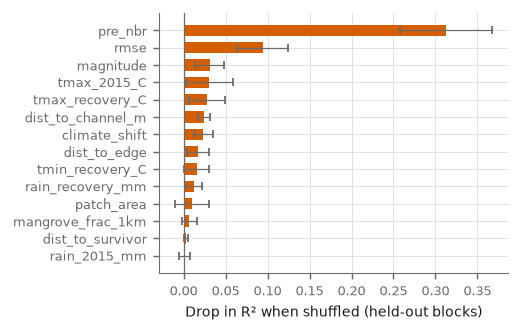


A covariate at or below zero carries no transferable signal.


In [6]:
gkf = GroupKFold(n_splits=n_splits)
imps = []
for tr_i, te_i in gkf.split(X, y, groups):
    rf.fit(X[tr_i], y[tr_i])
    r = permutation_importance(rf, X[te_i], y[te_i], n_repeats=10,
                               random_state=SEED, n_jobs=-1, scoring="r2")
    imps.append(r.importances_mean)
imps = np.array(imps)

imp = (pd.DataFrame({"covariate": COVARS,
                     "importance": imps.mean(axis=0),
                     "sd_across_folds": imps.std(axis=0)})
         .sort_values("importance", ascending=False)
         .reset_index(drop=True))
imp.to_csv(TABDIR / "table4_importance.csv", index=False)
MODEL["importance"] = imp.to_dict(orient="records")
print(imp.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(W1, 2.6)); tidy(ax)
o = imp.iloc[::-1]
ax.barh(o.covariate, o.importance, xerr=o.sd_across_folds,
        color=C_DIEBACK, height=0.65,
        error_kw=dict(ecolor=C_MUTED, elinewidth=0.7, capsize=2))
ax.axvline(0, color=C_MUTED, lw=0.7)
ax.set_xlabel("Drop in R² when shuffled (held-out blocks)")
fig.savefig(FIGDIR / "fig9_importance.png"); plt.show()

print("\nA covariate at or below zero carries no transferable signal.")
if imp.iloc[0].covariate == "rmse":
    print("*** rmse ranks first: the model is largely tracking data quality, ***")
    print("*** not ecology.  ***")

## 4. Partial dependence — what shape is the relationship?

Importance says *whether* a covariate matters. Partial dependence says *how*:
as this covariate increases, does predicted condition rise, fall, or turn?

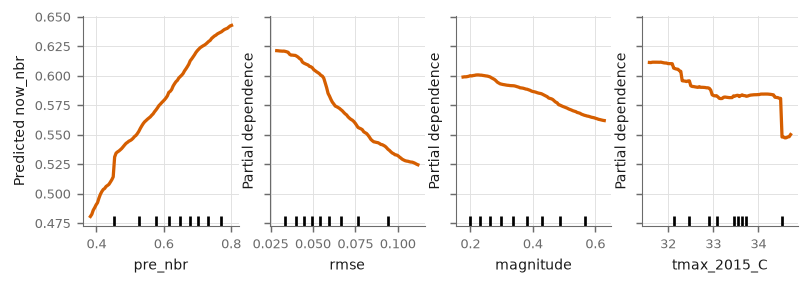

In [7]:
from sklearn.inspection import PartialDependenceDisplay

rf.fit(X, y)
top = imp.covariate.head(4).tolist()
idx = [COVARS.index(c) for c in top]

fig, axes = plt.subplots(1, len(top), figsize=(W2, 2.1), sharey=True)
PartialDependenceDisplay.from_estimator(
    rf, X, idx, feature_names=COVARS, ax=axes,
    line_kw=dict(color=C_DIEBACK, lw=1.8))
for a in np.atleast_1d(axes):
    tidy(a); a.set_title("")
np.atleast_1d(axes)[0].set_ylabel(f"Predicted {TARGET}")
fig.savefig(FIGDIR / "fig10_partial_dependence.png"); plt.show()

### 4b. Propagule limitation

The random forest can hide a real effect: when covariates are correlated it
spreads importance between them, and permutation importance then understates
any one of them. So the distance relationship is also examined on its own.

In [8]:
# The propagule-limitation test
if "dist_to_survivor" in d.columns or "dist_to_survivor" in COVARS:
    dd = px[np.isfinite(px.dist_to_survivor) & np.isfinite(px[TARGET])].copy()
    dd["region"] = np.where(dd.longitude < 138.5, "west", "east")

    print("median current NBR by distance to nearest surviving mangrove\n")
    for reg in ("west", "east", "all"):
        s = dd if reg == "all" else dd[dd.region == reg]
        if len(s) < 50:
            continue
        q = pd.qcut(s.dist_to_survivor, 5, duplicates="drop")
        g = s.groupby(q, observed=True).agg(
                n=(TARGET, "size"), nbr=(TARGET, "median"),
                unrec=("unrecovered", "mean"))
        print(f"--- {reg} ({len(s):,} pixels) ---")
        print(g.round(3).to_string())
        trend = g.nbr.iloc[-1] - g.nbr.iloc[0]
        print(f"    farthest minus nearest fifth: {trend:+.3f} NBR\n")
        if reg == "all":
            MODEL["propagule_trend_nbr"] = float(trend)

    # Block-bootstrapped correlation, WITHIN region so the east-west
    # gradient cannot masquerade as a distance effect.
    RNG_P = np.random.default_rng(SEED)
    def bb_spearman(x, y, lon, lat, block=BLOCK_DEG, n_boot=1000):
        from scipy import stats as _st
        ok = np.isfinite(x) & np.isfinite(y)
        x, y, lon, lat = (np.asarray(a)[ok] for a in (x, y, lon, lat))
        bid = (np.floor(lon/block).astype(int).astype(str) + "_" +
               np.floor(lat/block).astype(int).astype(str))
        bl, inv = np.unique(bid, return_inverse=True)
        if len(bl) < 3:
            return np.nan, np.nan, np.nan, len(bl)
        idx = [np.flatnonzero(inv == k) for k in range(len(bl))]
        pt = _st.spearmanr(x, y).statistic
        b = np.empty(n_boot)
        for i in range(n_boot):
            sel = np.concatenate([idx[p] for p in RNG_P.integers(0, len(bl), len(bl))])
            b[i] = _st.spearmanr(x[sel], y[sel]).statistic
        lo, hi = np.nanpercentile(b, [2.5, 97.5])
        return pt, lo, hi, len(bl)

    print("distance to nearest survivor vs current NBR, block-bootstrapped:")
    prop = {}
    for reg in ("west", "east", "all"):
        s = dd if reg == "all" else dd[dd.region == reg]
        r, lo, hi, nb = bb_spearman(s.dist_to_survivor, s[TARGET],
                                    s.longitude, s.latitude)
        clear = np.isfinite(lo) and (lo > 0 or hi < 0)
        print(f"  {reg:5s} rho={r:+.3f}  CI [{lo:+.3f}, {hi:+.3f}]  "
              f"{nb} blocks" + ("   <-- clear of zero" if clear else ""))
        prop[reg] = {"rho": float(r) if np.isfinite(r) else None,
                     "ci": [float(lo) if np.isfinite(lo) else None,
                            float(hi) if np.isfinite(hi) else None],
                     "n_blocks": int(nb), "ci_clear_of_zero": bool(clear)}
    MODEL["propagule_by_region"] = prop

    print("\nA NEGATIVE correlation clear of zero supports propagule limitation")
    

median current NBR by distance to nearest surviving mangrove

--- west (6,794 pixels) ---
                                      n    nbr  unrec
dist_to_survivor                                     
(28.63133842579, 28.63133842582]   3273  0.581  0.568
(28.63133842582, 29.78993145197]   1198  0.566  0.550
(29.78993145197, 41.31819884709]   1037  0.538  0.593
(41.31819884709, 159.57761296011]  1286  0.493  0.652
    farthest minus nearest fifth: -0.089 NBR

--- east (22,659 pixels) ---
                                    n    nbr  unrec
dist_to_survivor                                   
(28.6313384257, 28.6313384259]   5729  0.644  0.224
(28.6313384259, 29.789931452]    3660  0.642  0.203
(29.789931452, 41.3181988472]    4214  0.632  0.181
(41.3181988472, 66.1022965085]   4793  0.632  0.148
(66.1022965085, 216.2488726906]  4263  0.651  0.094
    farthest minus nearest fifth: +0.007 NBR

--- all (29,453 pixels) ---
                                      n    nbr  unrec
dist_to_survivor   

In [9]:
# 4c. Is the western distance effect really about propagules?
#
# Two things travel with distance to the nearest survivor and would
# produce the same pattern without any seed limitation at all:
#   severity  - pixels deeper inside a dead patch were often hit harder
#   site      - they may have been poorer stands to begin with
# The test is repeated inside strata of each. A relationship that
# survives both is not explained by either.

w = dd[dd.region == "west"].copy()
print(f"west: {len(w):,} pixels, distance "
      f"{w.dist_to_survivor.min():.0f}-{w.dist_to_survivor.max():.0f} m "
      f"({w.dist_to_survivor.max()/28.6:.1f} cells)\n")

rows = []
for strat in ("magnitude", "pre_nbr"):
    print(f"within quintiles of {strat}:")
    q = pd.qcut(w[strat], 5, duplicates="drop")
    for lev, s in w.groupby(q, observed=True):
        if len(s) < 200:
            continue
        r, lo, hi, nb = bb_spearman(s.dist_to_survivor, s[TARGET],
                                    s.longitude, s.latitude)
        clear = np.isfinite(lo) and (lo > 0 or hi < 0)
        print(f"  {lev}  n={len(s):6,}  rho={r:+.3f}  "
              f"CI [{lo:+.3f}, {hi:+.3f}]" + ("   <-- clear of zero" if clear else ""))
        rows.append({"stratified_by": strat, "stratum": str(lev), "n": len(s),
                     "rho": r, "lo": lo, "hi": hi, "clear_of_zero": clear})
    print()

conf = pd.DataFrame(rows)
conf.to_csv(TABDIR / "table4c_propagule_confounds.csv", index=False)
n_clear = int(conf.clear_of_zero.sum())
print(f"{n_clear} of {len(conf)} strata show a relationship clear of zero.")
MODEL["propagule_confound_strata_clear"] = n_clear
MODEL["propagule_confound_strata_total"] = int(len(conf))

west: 6,794 pixels, distance 29-160 m (5.6 cells)

within quintiles of magnitude:
  (0.0402, 0.259]  n= 1,359  rho=-0.099  CI [-0.165, -0.035]   <-- clear of zero
  (0.259, 0.354]  n= 1,359  rho=-0.127  CI [-0.220, -0.060]   <-- clear of zero
  (0.354, 0.448]  n= 1,358  rho=-0.136  CI [-0.189, -0.059]   <-- clear of zero
  (0.448, 0.556]  n= 1,359  rho=-0.105  CI [-0.159, +0.077]
  (0.556, 0.976]  n= 1,359  rho=-0.060  CI [-0.152, +0.240]

within quintiles of pre_nbr:
  (0.105, 0.613]  n= 1,359  rho=-0.028  CI [-0.088, +0.068]
  (0.613, 0.679]  n= 1,359  rho=-0.134  CI [-0.226, +0.024]
  (0.679, 0.729]  n= 1,358  rho=-0.245  CI [-0.293, -0.092]   <-- clear of zero
  (0.729, 0.787]  n= 1,359  rho=-0.266  CI [-0.330, -0.057]   <-- clear of zero
  (0.787, 1.08]  n= 1,359  rho=-0.254  CI [-0.331, -0.020]   <-- clear of zero

6 of 10 strata show a relationship clear of zero.


116 coastal segments of ~6 km with at least 30 dieback pixels
covering 2,424 ha of 2,522 ha mapped as dieback

TEN SEGMENTS LEAST LIKELY TO RECOVER
 rank     lon     lat region  dieback_ha  frac_unrecovered  unrec_lo  unrec_hi
    1 135.275 -14.725   west       5.310             1.000     1.000     1.000
    2 135.475 -14.675   west       3.254             0.947     0.868     1.000
    3 135.775 -14.225   west       6.509             0.895     0.829     0.961
    4 141.075 -16.825   east       7.279             0.894     0.824     0.953
    5 136.575 -15.825   west       3.511             0.878     0.756     0.976
    6 135.375 -14.775   west      95.573             0.877     0.859     0.896
    7 136.625 -15.725   west       3.083             0.861     0.750     0.972
    8 136.675 -15.825   west       2.740             0.844     0.719     0.969
    9 135.375 -14.725   west       8.821             0.816     0.738     0.883
   10 136.725 -15.875   west       4.625             0.815    

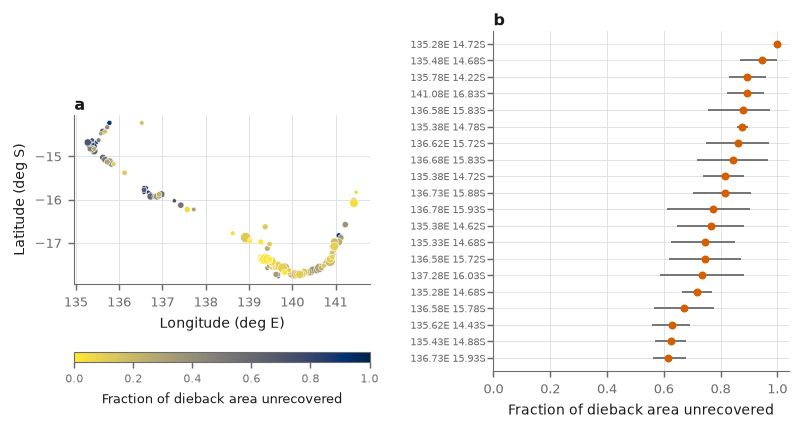

In [10]:
 # 5. recovery capacity by coastal segment

SEG_DEG = 0.05          # ~5 km
MIN_PIX = 30
N_BOOT  = 1000
 
seg = px.copy()
seg["sx"] = np.floor(seg.longitude / SEG_DEG) * SEG_DEG
seg["sy"] = np.floor(seg.latitude  / SEG_DEG) * SEG_DEG
 
rng_s = np.random.default_rng(SEED)
rows = []
for (sx, sy), s in seg.groupby(["sx", "sy"], observed=True):
    if len(s) < MIN_PIX:
        continue
    u = s.unrecovered.values.astype(float)
    r = s.recovery_ratio_adj.values
    b = rng_s.integers(0, len(u), (N_BOOT, len(u)))
    lo, hi = np.percentile(u[b].mean(axis=1), [2.5, 97.5])
    rows.append({
        "lon": sx + SEG_DEG/2, "lat": sy + SEG_DEG/2,
        "region": "west" if sx < 138.5 else "east",
        "n_pixels": len(s), "dieback_ha": len(s) * PIXEL_HA,
        "median_recovery_adj": float(np.nanmedian(r)),
        "frac_unrecovered": float(u.mean()),
        "unrec_lo": float(lo), "unrec_hi": float(hi)})
 
cap = pd.DataFrame(rows).sort_values("frac_unrecovered", ascending=False)
cap.insert(0, "rank", np.arange(1, len(cap) + 1))
cap.to_csv(TABDIR / "table5_recovery_capacity.csv", index=False)
 
print(f"{len(cap)} coastal segments of ~{SEG_DEG*111:.0f} km "
      f"with at least {MIN_PIX} dieback pixels")
print(f"covering {cap.dieback_ha.sum():,.0f} ha of "
      f"{len(px)*PIXEL_HA:,.0f} ha mapped as dieback\n")
 
print("TEN SEGMENTS LEAST LIKELY TO RECOVER")
show = cap.head(10)[["rank", "lon", "lat", "region", "dieback_ha",
                     "frac_unrecovered", "unrec_lo", "unrec_hi"]]
print(show.round(3).to_string(index=False))
 
print("\nby region:")
print(cap.groupby("region").agg(
        segments=("rank", "size"),
        dieback_ha=("dieback_ha", "sum"),
        median_unrecovered=("frac_unrecovered", "median")).round(3).to_string())
 
MODEL["capacity_segments"] = int(len(cap))
MODEL["capacity_worst"] = show.head(5).to_dict("records")
 
# Figure 11 - the capacity surface, ranked with its uncertainty 
fig, (a1, a2) = plt.subplots(1, 2, figsize=(W2, 3.4),
                             gridspec_kw={"width_ratios": [1.0, 1.0],
                                          "wspace": 0.42})
 
sc = a1.scatter(cap.lon, cap.lat, s=np.sqrt(cap.dieback_ha) * 3.2,
                c=cap.frac_unrecovered, cmap="cividis_r",
                vmin=0, vmax=1, linewidths=0.3, edgecolors="white")
a1.set_xlabel("Longitude (deg E)"); a1.set_ylabel("Latitude (deg S)")
a1.set_aspect("equal"); tidy(a1)
a1.set_title("a", loc="left", fontweight="bold", fontsize=9, pad=3)
 
# colourbar BELOW the map, so it cannot collide with panel b's labels
cb = fig.colorbar(sc, ax=a1, orientation="horizontal",
                  fraction=0.055, pad=0.20, aspect=32)
cb.set_label("Fraction of dieback area unrecovered", fontsize=7)
cb.ax.tick_params(labelsize=6)
 
top = cap.head(20).iloc[::-1]
ypos = np.arange(len(top))
a2.hlines(ypos, top.unrec_lo, top.unrec_hi, color=C_MUTED, lw=1.0)
a2.plot(top.frac_unrecovered, ypos, "o", ms=3.4, color=C_DIEBACK)
a2.set_yticks(ypos)
a2.set_yticklabels([f"{r.lon:.2f}E {abs(r.lat):.2f}S" for r in top.itertuples()],
                   fontsize=5.8)
a2.tick_params(axis="y", pad=1)
a2.set_xlabel("Fraction of dieback area unrecovered")
a2.set_xlim(0, 1.04); a2.set_ylim(-0.8, len(top) - 0.2)
a2.set_title("b", loc="left", fontweight="bold", fontsize=9, pad=3)
tidy(a2)
 
fig.savefig(FIGDIR / "fig11_recovery_capacity.png", bbox_inches="tight")
plt.show()

## 5. Save

In [11]:
def clean(o):
    if isinstance(o, dict):  return {k: clean(v) for k,v in o.items()}
    if isinstance(o, list):  return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    return o
with open(TABDIR / "model_performance.json", "w") as f:
    json.dump(clean(MODEL), f, indent=2)
print("written: tables/table4_importance.csv, tables/model_performance.json,")
print("         figures/fig9_importance.png, figures/fig10_partial_dependence.png")
print("         data/pixels_with_covariates.csv")

written: tables/table4_importance.csv, tables/model_performance.json,
         figures/fig9_importance.png, figures/fig10_partial_dependence.png
         data/pixels_with_covariates.csv


## 6. PREDICTED recovery capacity for coast not yet hit

projection predictors: ['pre_nbr', 'dist_to_edge', 'mangrove_frac_1km', 'climate_shift', 'rmse', 'dist_to_channel_m', 'rain_2015_mm', 'rain_recovery_mm', 'tmax_2015_C', 'tmax_recovery_C', 'tmin_recovery_C']
765,138 undisturbed mangrove pixels
  joined dist_to_channel_m.csv
  joined rain_2015_mm.csv
  joined rain_recovery_mm.csv
  joined tmax_2015_C.csv
  joined tmax_recovery_C.csv
  joined tmin_recovery_C.csv
765,138 of 765,138 undisturbed pixels have every covariate (100.0%)

predicted current NBR after a 2015-16-type event:
  median 0.513, against observed pre-event median 0.574
  median predicted deficit +0.038 NBR
  median per-tree SD 0.097

484 undisturbed coastal segments of ~6 km, 65,467 ha

TEN SEGMENTS PREDICTED LEAST ABLE TO RECOVER
 rank     lon     lat region  mangrove_ha  pre_nbr  pred_deficit  pred_sd
    1 135.375 -14.725   west      597.847    0.624         0.259    0.113
    2 135.425 -14.625   west       23.808    0.554         0.247    0.108
    3 135.325 -14.725   w

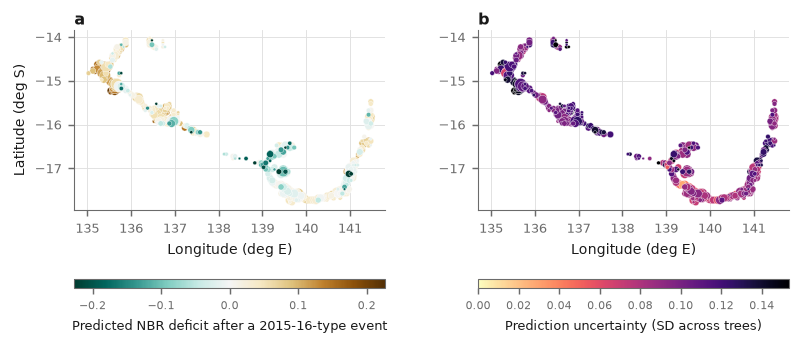


written: tables/table7_predicted_capacity.csv,
         figures/fig12_predicted_capacity.png


In [12]:
# 6. PREDICTED recovery capacity for coast not yet hit

from scipy.spatial import cKDTree
 
PROJ_COVARS = [c for c in COVARS
               if c not in ("magnitude", "dist_to_survivor", "patch_area")]
print("projection predictors:", PROJ_COVARS)
 
# 1. the undisturbed pixels 
UND = DATA / "undisturbed_census.csv"
assert UND.exists(), (
    f"{UND} not found. It is the GEE export from 09_undisturbed_census.js "
    "and carries pre_nbr, now_nbr, climate_shift and rmse for every "
    "class-1 pixel.")
 
un = pd.read_csv(UND).replace(-9999, np.nan)
print(f"{len(un):,} undisturbed mangrove pixels")
 
# 2. geometric covariates
with rasterio.open(RASTER_CLASS) as src:
    tr, Hh, Ww = src.transform, src.height, src.width
    res_deg = abs(tr.a)
    mang, bnd = [], []
    for _, win in src.block_windows(1):
        r0, c0 = int(win.row_off), int(win.col_off)
        a = src.read(1, window=win)
        if not a.any():
            continue
        m = a > 0
        e = m & ~ndimage.binary_erosion(m, np.ones((3, 3), bool))
        for mask, store in ((m, mang), (e, bnd)):
            r, c = np.nonzero(mask)
            if len(r):
                store.append(np.column_stack([r + r0, c + c0]).astype(np.int32))
mang = np.vstack(mang); bnd = np.vstack(bnd)
 
rows, cols = rasterio.transform.rowcol(tr, un.longitude.values, un.latitude.values)
rows = np.clip(np.asarray(rows), 0, Hh - 1)
cols = np.clip(np.asarray(cols), 0, Ww - 1)
 
LAT_MID = float(np.nanmedian(px.latitude))
MX = res_deg * 111320 * np.cos(np.radians(LAT_MID))
MY = res_deg * 110540
to_m = lambda rc: np.column_stack([rc[:, 1] * MX, rc[:, 0] * MY])
P = to_m(np.column_stack([rows, cols]))
 
un["dist_to_edge"] = cKDTree(to_m(bnd)).query(P, k=1)[0]
n_in = cKDTree(to_m(mang)).query_ball_point(P, r=500.0, return_length=True)
un["mangrove_frac_1km"] = np.clip(n_in / (np.pi * 500.0**2 / (MX * MY)), 0, 1)
 
# 3. the external covariates
cov_dir = DATA / "covariates"
for f in sorted(cov_dir.glob("*.csv")):
    name = f.stem
    if name not in PROJ_COVARS:
        continue
    c = pd.read_csv(f)
    t = cKDTree(c[["longitude", "latitude"]].values)
    _, idx = t.query(un[["longitude", "latitude"]].values, k=1)
    un[name] = c.value.values[idx]
    print(f"  joined {f.name}")
 
missing = [c for c in PROJ_COVARS if c not in un.columns]
assert not missing, f"no values for {missing} on the undisturbed pixels"
 
before = len(un)
un = un.dropna(subset=PROJ_COVARS + ["pre_nbr"])
print(f"{len(un):,} of {before:,} undisturbed pixels have every covariate "
      f"({len(un)/before:.1%})")
 
# 4. fit on the disturbed pixels, predict on the undisturbed
rf_proj = RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                max_features="sqrt", n_jobs=-1,
                                random_state=SEED)
rf_proj.fit(d[PROJ_COVARS].values, y)
 
Xu = un[PROJ_COVARS].values

s1 = np.zeros(len(un)); s2 = np.zeros(len(un))
for t in rf_proj.estimators_:
    p = t.predict(Xu)
    s1 += p; s2 += p * p
n_tree = len(rf_proj.estimators_)
pred = s1 / n_tree
sd   = np.sqrt(np.maximum(s2 / n_tree - pred**2, 0))
 
un["pred_now_nbr"] = pred
un["pred_sd"]      = sd
un["pred_deficit"] = un.pre_nbr - pred        # capacity: higher = worse
 
print(f"\npredicted current NBR after a 2015-16-type event:")
print(f"  median {np.median(pred):.3f}, against observed pre-event "
      f"median {un.pre_nbr.median():.3f}")
print(f"  median predicted deficit {un.pred_deficit.median():+.3f} NBR")
print(f"  median per-tree SD {np.median(sd):.3f}")
 
# 5. aggregate to the same segments 
un["sx"] = np.floor(un.longitude / SEG_DEG) * SEG_DEG
un["sy"] = np.floor(un.latitude  / SEG_DEG) * SEG_DEG
 
cap_p = (un.groupby(["sx", "sy"], observed=True)
           .agg(n_pixels=("pred_deficit", "size"),
                pred_deficit=("pred_deficit", "median"),
                pred_sd=("pred_sd", "median"),
                pre_nbr=("pre_nbr", "median"))
           .reset_index())
cap_p = cap_p[cap_p.n_pixels >= MIN_PIX].copy()
cap_p["lon"] = cap_p.sx + SEG_DEG/2
cap_p["lat"] = cap_p.sy + SEG_DEG/2
cap_p["region"] = np.where(cap_p.sx < 138.5, "west", "east")
cap_p["mangrove_ha"] = cap_p.n_pixels * PIXEL_HA
cap_p = cap_p.sort_values("pred_deficit", ascending=False)
cap_p.insert(0, "rank", np.arange(1, len(cap_p) + 1))
cap_p.to_csv(TABDIR / "table7_predicted_capacity.csv", index=False)
 
print(f"\n{len(cap_p)} undisturbed coastal segments of ~{SEG_DEG*111:.0f} km, "
      f"{cap_p.mangrove_ha.sum():,.0f} ha")
print("\nTEN SEGMENTS PREDICTED LEAST ABLE TO RECOVER")
print(cap_p.head(10)[["rank", "lon", "lat", "region", "mangrove_ha",
                      "pre_nbr", "pred_deficit", "pred_sd"]]
      .round(3).to_string(index=False))
print("\nby region:")
print(cap_p.groupby("region").agg(
        segments=("rank", "size"), mangrove_ha=("mangrove_ha", "sum"),
        median_deficit=("pred_deficit", "median")).round(3).to_string())
 
MODEL["predicted_capacity"] = {
    "n_segments": int(len(cap_p)),
    "r2_blocked_projection": float(MODEL["ablation"].get("projectable set", np.nan)),
    "median_deficit": float(cap_p.pred_deficit.median()),
    "worst": cap_p.head(5)[["lon", "lat", "region", "mangrove_ha",
                            "pred_deficit"]].to_dict("records")}
 
# 6. Figure 12 
fig, (a1, a2) = plt.subplots(1, 2, figsize=(W2, 3.4),
                             gridspec_kw={"wspace": 0.30})
 
vlim = float(np.nanpercentile(np.abs(cap_p.pred_deficit), 98))
sc = a1.scatter(cap_p.lon, cap_p.lat, s=np.sqrt(cap_p.mangrove_ha) * 1.3,
                c=cap_p.pred_deficit, cmap="BrBG_r",
                vmin=-vlim, vmax=vlim,
                linewidths=0.2, edgecolors="white")
a1.set_xlabel("Longitude (deg E)"); a1.set_ylabel("Latitude (deg S)")
a1.set_aspect("equal"); tidy(a1)
a1.set_title("a", loc="left", fontweight="bold", fontsize=9, pad=3)
cb = fig.colorbar(sc, ax=a1, orientation="horizontal",
                  fraction=0.055, pad=0.20, aspect=32)
cb.set_label("Predicted NBR deficit after a 2015-16-type event", fontsize=7)
cb.ax.tick_params(labelsize=6)
 
sc2 = a2.scatter(cap_p.lon, cap_p.lat, s=np.sqrt(cap_p.mangrove_ha) * 1.3,
                 c=cap_p.pred_sd, cmap="magma_r",
                 vmin=0, vmax=float(np.nanpercentile(cap_p.pred_sd, 98)),
                 linewidths=0.2, edgecolors="white")
a2.set_xlabel("Longitude (deg E)")
a2.set_aspect("equal"); tidy(a2)
a2.set_title("b", loc="left", fontweight="bold", fontsize=9, pad=3)
cb2 = fig.colorbar(sc2, ax=a2, orientation="horizontal",
                   fraction=0.055, pad=0.20, aspect=32)
cb2.set_label("Prediction uncertainty (SD across trees)", fontsize=7)
cb2.ax.tick_params(labelsize=6)
 
fig.savefig(FIGDIR / "fig12_predicted_capacity.png", bbox_inches="tight")
plt.show()
 
print(f"\nwritten: tables/table7_predicted_capacity.csv,")
print(f"         figures/fig12_predicted_capacity.png")

calibrated cut: pred_now / pre_nbr < 0.845  (90.2% agreement on 29,453 pixels)
vulnerable 17,897 ha  |  west 44.2%  east 6.9%
display: 1,054 cells of ~3 km; median dominant-class share 92%
  + Esri boundaries and places overlay
basemap: esri_imagery, zoom 8
  


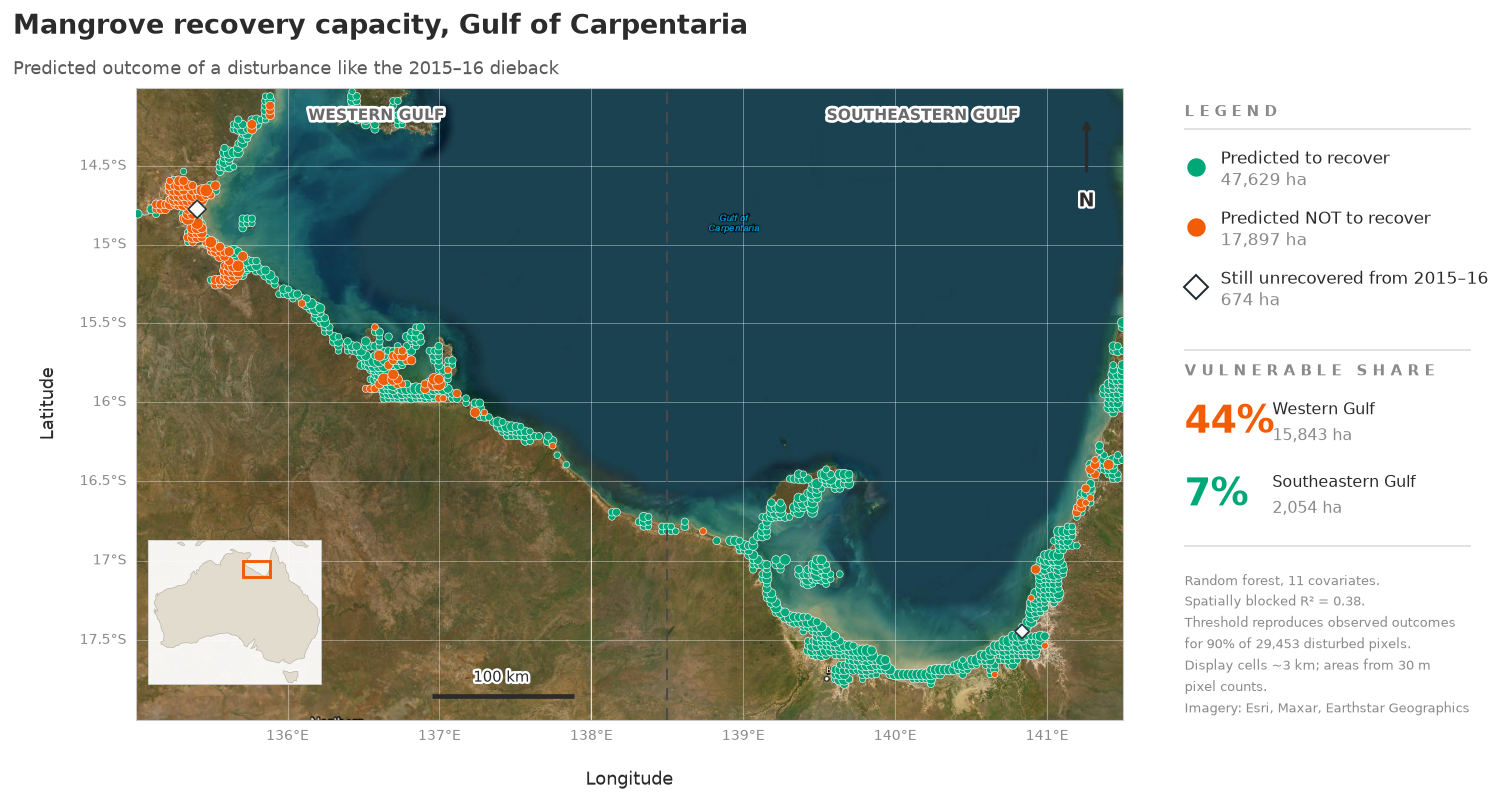


predicted vulnerability of undisturbed mangrove:
region  mangrove_ha  vulnerable_ha  vulnerable_pct
  east      29691.4         2053.5             6.9
  west      35834.4        15843.4            44.2

written: figures/fig13_future_capacity_map.png


In [39]:
# 7. Figure 13 - the headline map

from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
import matplotlib.patheffects as pe
 
BASEMAP   = "esri_imagery"
TILE_ZOOM = 8            
OVERLAY_LABELS = True    
OVERLAY_RIVERS = True    
TITLE     = True         
 
GULF = {"lon": (135.0, 141.5), "lat": (-18.0, -14.0)}
C_OK, C_BAD = "#00A878", "#F25C05"
 

C_GONE = "#FFFFFF"
C_TEXT, C_FAINT = "#2b2b2b", "#8a8a8a"
 
# calibrate 
obs_ratio = (px[TARGET] / px.pre_nbr).values
obs_unrec = px.unrecovered.values.astype(bool)
ok = np.isfinite(obs_ratio) & np.isfinite(obs_unrec)
cands = np.arange(0.50, 1.01, 0.005)
acc = [((obs_ratio[ok] < t) == obs_unrec[ok]).mean() for t in cands]
CUT, ACC = float(cands[int(np.argmax(acc))]), float(np.max(acc))
print(f"calibrated cut: pred_now / pre_nbr < {CUT:.3f}  "
      f"({ACC:.1%} agreement on {ok.sum():,} pixels)")
MODEL["capacity_cut"] = {"ratio": CUT, "agreement": ACC}
 
un["pred_ratio"] = un.pred_now_nbr / un.pre_nbr
un["vulnerable"] = un.pred_ratio < CUT
un["region"]     = np.where(un.longitude < 138.5, "west", "east")
obs_still = px[px.unrecovered.astype(bool)]
vuln_ha, gone_ha = un.vulnerable.sum()*PIXEL_HA, len(obs_still)*PIXEL_HA
w, e = un[un.region == "west"], un[un.region == "east"]
pct_w, pct_e = w.vulnerable.mean()*100, e.vulnerable.mean()*100
print(f"vulnerable {vuln_ha:,.0f} ha  |  west {pct_w:.1f}%  east {pct_e:.1f}%")
 
# display grid, ~3 km 
DISP = 0.03
gx = np.arange(GULF["lon"][0], GULF["lon"][1] + DISP, DISP)
gy = np.arange(GULF["lat"][0], GULF["lat"][1] + DISP, DISP)
GXe, GYe = np.meshgrid(gx, gy)
def count(lon, lat):
    h, _, _ = np.histogram2d(lat, lon, bins=[gy, gx])
    return h
 

cnt = np.stack([
    count(un.loc[~un.vulnerable, "longitude"], un.loc[~un.vulnerable, "latitude"]),
    count(un.loc[un.vulnerable, "longitude"],  un.loc[un.vulnerable, "latitude"]),
    count(obs_still.longitude, obs_still.latitude)])
tot  = cnt.sum(axis=0)
who  = np.argmax(cnt, axis=0)
share = np.where(tot > 0, cnt.max(axis=0) / np.maximum(tot, 1), np.nan)
print(f"display: {int((tot>0).sum()):,} cells of ~{DISP*111:.0f} km; "
      f"median dominant-class share {np.nanmedian(share):.0%}")
 
layers = [
    (C_OK,   "Predicted to recover",
     f"{(len(un)-un.vulnerable.sum())*PIXEL_HA:,.0f} ha"),
    (C_BAD,  "Predicted NOT to recover", f"{vuln_ha:,.0f} ha"),
    (C_GONE, "Still unrecovered from 2015\u201316", f"{gone_ha:,.0f} ha"),
]
 
# canvas 
fig = plt.figure(figsize=(12.0, 6.4))
fig.patch.set_facecolor("#ffffff")
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 0.30], wspace=0.02,
                      left=0.105, right=0.985, top=0.885, bottom=0.125)
 
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.img_tiles as cimgt
from cartopy.io import shapereader
pc = ccrs.PlateCarree()
 
class _Esri(cimgt.GoogleTiles):
    
    def __init__(self, service, form="RGB", **kw):
        self.service = service
        super().__init__(desired_tile_form=form, **kw)
    def _image_url(self, tile):
        x, y, z = tile
        return ("https://server.arcgisonline.com/ArcGIS/rest/services/"
                f"{self.service}/MapServer/tile/{z}/{y}/{x}")
 
TILERS = {
    "esri_topo":    (lambda: _Esri("World_Topo_Map"),
                     "Basemap: Esri, HERE, Garmin, USGS"),
    "esri_natgeo":  (lambda: _Esri("NatGeo_World_Map"),
                     "Basemap: Esri, National Geographic"),
    "esri_street":  (lambda: _Esri("World_Street_Map"),
                     "Basemap: Esri, HERE, Garmin"),
    "esri_imagery": (lambda: _Esri("World_Imagery"),
                     "Imagery: Esri, Maxar, Earthstar Geographics"),
    "osm":          (cimgt.OSM, "© OpenStreetMap contributors"),
}
 
SRC, mode = "Basemap: Natural Earth", "vector"
if BASEMAP in TILERS:
    try:
        maker, SRC = TILERS[BASEMAP]
        tiler = maker()
        ax = fig.add_subplot(gs[0, 0], projection=tiler.crs)
        ax.set_extent([*GULF["lon"], *GULF["lat"]], crs=pc)
        ax.add_image(tiler, TILE_ZOOM)
        
        if BASEMAP == "esri_imagery" and OVERLAY_LABELS:
            try:
                ax.add_image(
                    _Esri("Reference/World_Boundaries_and_Places", form="RGBA"),
                    TILE_ZOOM, zorder=2)
                print("  + Esri boundaries and places overlay")
            except Exception as ox:
                print(f"  overlay unavailable ({type(ox).__name__}) - "
                      "set OVERLAY_LABELS = False if the map looks wrong")
        fig.canvas.draw()          # force the fetch now, so it can be caught
        mode = BASEMAP
        print(f"basemap: {BASEMAP}, zoom {TILE_ZOOM}")
    except Exception as ex:
        print(f"tile service unreachable ({type(ex).__name__}) - "
              "falling back to Natural Earth")
        fig.clf()
        gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 0.30], wspace=0.02,
                              left=0.105, right=0.985, top=0.885, bottom=0.125)
        BASEMAP, SRC = "vector", "Basemap: Natural Earth"
 
if BASEMAP == "vector":
    ax = fig.add_subplot(gs[0, 0], projection=pc)
    ax.set_extent([*GULF["lon"], *GULF["lat"]], crs=pc)
    def ne(cat, name, res="10m"):
        shapereader.natural_earth(resolution=res, category=cat, name=name)
        return cfeature.NaturalEarthFeature(cat, name, res)
    for nm, fn in [
        ("ocean",  lambda: ax.add_feature(ne("physical", "ocean"),
                     facecolor="#c4dcea", edgecolor="none", zorder=0)),
        ("land",   lambda: ax.add_feature(ne("physical", "land"),
                     facecolor="#ece7db", edgecolor="none", zorder=1)),
        ("rivers", lambda: ax.add_feature(
                     ne("physical", "rivers_lake_centerlines"),
                     facecolor="none", edgecolor="#7fb3cc", lw=0.7, zorder=2)),
        ("coast",  lambda: ax.add_feature(ne("physical", "coastline"),
                     facecolor="none", edgecolor="#ffffff", lw=0.9, zorder=3)),
    ]:
        try: fn()
        except Exception as ex: print(f"  skipped {nm} ({type(ex).__name__})")
    print("basemap: Natural Earth 10 m")
 
if mode != "vector" and OVERLAY_RIVERS:
    try:
        shapereader.natural_earth(resolution="10m", category="physical",
                                  name="rivers_lake_centerlines")
        ax.add_feature(cfeature.NaturalEarthFeature(
            "physical", "rivers_lake_centerlines", "10m"),
            facecolor="none", edgecolor="#8ecae6", linewidth=0.8,
            alpha=0.85, zorder=3)
        print("  ")
    except Exception as rx:
        print(f"  rivers unavailable ({type(rx).__name__})")
 
gl = ax.gridlines(draw_labels=True, linewidth=0.4, color="#ffffff",
                  alpha=0.5, zorder=6)
_pos = ax.get_position()
fig.text(_pos.x0 + _pos.width / 2, _pos.y0 - 0.072, "Longitude",
         ha="center", va="center", fontsize=10, color=C_TEXT)
fig.text(_pos.x0 - 0.056, _pos.y0 + _pos.height / 2, "Latitude",
         ha="center", va="center", rotation=90, fontsize=10, color=C_TEXT)
gl.top_labels = False; gl.right_labels = False
gl.xlabel_style = {"size": 8, "color": C_FAINT}
gl.ylabel_style = {"size": 8, "color": C_FAINT}
for s in ax.spines.values():
    s.set_edgecolor("#c8c8c8"); s.set_linewidth(0.6)
 
# the data
cx = (gx[:-1] + gx[1:]) / 2.0
cy = (gy[:-1] + gy[1:]) / 2.0
CXc, CYc = np.meshgrid(cx, cy)
sel   = tot > 0
sizes = 12.0 + 46.0 * np.sqrt(tot / max(tot.max(), 1))
 
MARKER = ["o", "o", "D"]            # diamond for the observed loss
EDGE   = ["#ffffff", "#ffffff", "#1F2933"]
EWID   = [0.35, 0.35, 0.9]
GROW   = [1.0, 1.0, 1.5]
 
for k, (col, lab, _) in enumerate(layers):
    m = sel & (who == k)
    if not m.any():
        continue
    ax.scatter(CXc[m], CYc[m], s=sizes[m] * GROW[k], c=col,
               marker=MARKER[k], linewidths=EWID[k], edgecolors=EDGE[k],
               alpha=0.95, transform=pc, zorder=4 + k)
 
ax.plot([138.5, 138.5], [GULF["lat"][0], GULF["lat"][1]], color="#4a4a4a",
        lw=1.1, linestyle=(0, (6, 4)), zorder=8, transform=pc)

for lonlab, lab in [(136.6, "WESTERN GULF"), (140.2, "SOUTHEASTERN GULF")]:
    ax.text(lonlab, -14.18, lab, ha="center", va="center", fontsize=8.6,
            fontweight="bold", color="#6a6a6a", zorder=9, transform=pc
            ).set_path_effects([pe.withStroke(linewidth=3.0,
                                              foreground="#ffffff")])
 
km = 100 / (111.320 * np.cos(np.radians(-16.0)))
x0, y0 = 136.95, -17.85
ax.plot([x0, x0+km], [y0, y0], color=C_TEXT, lw=2.6, solid_capstyle="butt",
        zorder=12, transform=pc)
ax.text(x0+km/2, y0+0.09, "100 km", ha="center", fontsize=8.2,
        color=C_TEXT, zorder=12, transform=pc).set_path_effects(
            [pe.withStroke(linewidth=2.6, foreground="#ffffff")])
 
ax.annotate("", xy=(0.963, 0.955), xytext=(0.963, 0.862),
            xycoords="axes fraction", textcoords="axes fraction",
            arrowprops=dict(arrowstyle="-|>", color=C_TEXT, lw=1.8), zorder=13)
ax.annotate("N", xy=(0.963, 0.835), xycoords="axes fraction", ha="center",
            va="top", fontsize=10.5, fontweight="bold", color=C_TEXT,
            zorder=13).set_path_effects(
                [pe.withStroke(linewidth=2.6, foreground="#ffffff")])
 
if TITLE:
    fig.text(0.045, 0.975, "Mangrove recovery capacity, Gulf of Carpentaria",
             ha="left", va="top", fontsize=15, fontweight="bold", color=C_TEXT)
    fig.text(0.045, 0.918, "Predicted outcome of a disturbance like the "
             "2015–16 dieback", ha="left", va="top", fontsize=10,
             color="#5a5a5a")
 
# legend and statistics column 
axL = fig.add_subplot(gs[0, 1]); axL.axis("off")
axL.set_xlim(0, 1); axL.set_ylim(0, 1)
axL.text(0.06, 0.955, "L E G E N D", fontsize=8.2, fontweight="bold",
         color=C_FAINT, transform=axL.transAxes)
axL.plot([0.06, 0.97], [0.935, 0.935], color="#dcdcdc", lw=0.9,
         transform=axL.transAxes)
for i, (col, lab, val) in enumerate(layers):
    y = 0.875 - i*0.095
    axL.plot([0.095], [y], marker=MARKER[i], ms=11 if i < 2 else 9.5,
             color=col, mec=EDGE[i], mew=0.8 if i < 2 else 1.1,
             transform=axL.transAxes, clip_on=False)
    axL.text(0.175, y+0.012, lab, fontsize=9.2, va="center", color=C_TEXT,
             transform=axL.transAxes)
    axL.text(0.175, y-0.022, val, fontsize=9.2, va="center", color=C_FAINT,
             transform=axL.transAxes)
axL.plot([0.06, 0.97], [0.585, 0.585], color="#dcdcdc", lw=0.9,
         transform=axL.transAxes)
axL.text(0.06, 0.545, "V U L N E R A B L E   S H A R E", fontsize=8.2,
         fontweight="bold", color=C_FAINT, transform=axL.transAxes)
for i, (name, pct, ha) in enumerate(
        [("Western Gulf", pct_w, w.vulnerable.sum()*PIXEL_HA),
         ("Southeastern Gulf", pct_e, e.vulnerable.sum()*PIXEL_HA)]):
    yy = 0.470 - i*0.115
    axL.text(0.06, yy, f"{pct:.0f}%", fontsize=21, fontweight="bold",
             color=C_BAD if pct > 20 else C_OK, va="center",
             transform=axL.transAxes)
    axL.text(0.34, yy+0.020, name, fontsize=8.8, color=C_TEXT, va="center",
             transform=axL.transAxes)
    axL.text(0.34, yy-0.021, f"{ha:,.0f} ha", fontsize=8.8, color=C_FAINT,
             va="center", transform=axL.transAxes)
axL.plot([0.06, 0.97], [0.275, 0.275], color="#dcdcdc", lw=0.9,
         transform=axL.transAxes)
axL.text(0.06, 0.238,
         f"Random forest, {len(PROJ_COVARS)} covariates.\n"
         f"Spatially blocked R² = "
         f"{MODEL['ablation'].get('projectable set', float('nan')):.2f}.\n"
         f"Threshold reproduces observed outcomes\nfor {ACC:.0%} of "
         f"{ok.sum():,} disturbed pixels.\n"
         f"Display cells ~3 km; areas from 30 m\npixel counts.\n{SRC}",
         fontsize=7.4, color=C_FAINT, va="top", linespacing=1.6,
         transform=axL.transAxes)
try:
    
    shapereader.natural_earth(resolution="110m", category="physical",
                              name="land")
    axl = ax.inset_axes([0.013, 0.020, 0.175, 0.300], projection=pc)
    axl.set_extent([112, 154, -44, -9], crs=pc)
    axl.add_feature(cfeature.NaturalEarthFeature("physical", "land", "110m"),
                    facecolor="#e2dccf", edgecolor="#b6b0a4", linewidth=0.35)
    axl.add_patch(Rectangle((GULF["lon"][0], GULF["lat"][0]),
                            GULF["lon"][1]-GULF["lon"][0],
                            GULF["lat"][1]-GULF["lat"][0], fill=False,
                            edgecolor=C_BAD, lw=1.6, transform=pc, zorder=5))
    axl.set_facecolor("#ffffff")
    axl.patch.set_alpha(0.94)
    for s in axl.spines.values():
        s.set_edgecolor("#cfcfcf"); s.set_linewidth(0.5)
except Exception as ex:
    print(f"  skipped locator inset ({type(ex).__name__})")
 
fig.savefig(FIGDIR / "fig13_future_capacity_map.png", dpi=400,
            bbox_inches="tight", pad_inches=0.08, facecolor="#ffffff")
plt.show()
 
tab = (un.groupby("region")
         .agg(mangrove_ha=("vulnerable", lambda s: len(s) * PIXEL_HA),
              vulnerable_ha=("vulnerable", lambda s: s.sum() * PIXEL_HA),
              vulnerable_pct=("vulnerable", "mean")).reset_index())
tab["vulnerable_pct"] = (tab.vulnerable_pct * 100).round(1)
tab.to_csv(TABDIR / "table8_future_vulnerability.csv", index=False)
print("\npredicted vulnerability of undisturbed mangrove:")
print(tab.round(1).to_string(index=False))
MODEL["future_vulnerability"] = tab.to_dict("records")
print("\nwritten: figures/fig13_future_capacity_map.png")